# Z(p) and d' — signal detection theory

Z(p) is the inverse of the Gaussian CDF (the probit function).
d' = Z(hit rate) - Z(false alarm rate)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

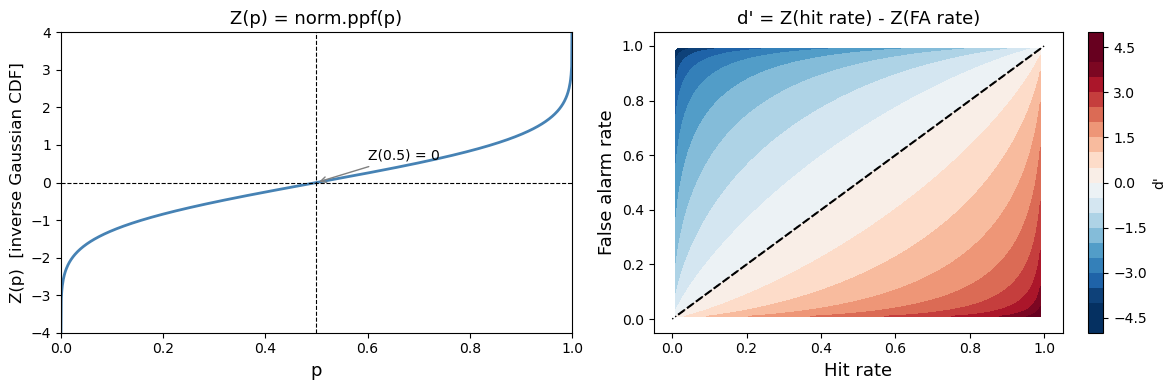

In [2]:
p = np.linspace(0, 1, 1000)

# Z(p) is undefined at exactly 0 and 1; clip to avoid -/+inf for display
p_safe = np.clip(p, 1e-6, 1 - 1e-6)
z = norm.ppf(p_safe)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ── left: Z(p) vs p ──────────────────────────────────────────────────
ax = axes[0]
ax.plot(p, z, color='steelblue', lw=2)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.axvline(0.5, color='k', lw=0.8, ls='--')
ax.set_xlabel('p', fontsize=13)
ax.set_ylabel('Z(p)  [inverse Gaussian CDF]', fontsize=12)
ax.set_title('Z(p) = norm.ppf(p)', fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(-4, 4)
ax.annotate('Z(0.5) = 0', xy=(0.5, 0), xytext=(0.6, 0.6),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=10)

# ── right: d' heat map over hit rate x false alarm rate ─────────────
ax = axes[1]
hr  = np.linspace(0.01, 0.99, 200)
far = np.linspace(0.01, 0.99, 200)
HR, FAR = np.meshgrid(hr, far)
dprime  = norm.ppf(HR) - norm.ppf(FAR)

im = ax.contourf(hr, far, dprime, levels=20, cmap='RdBu_r', vmin=-4, vmax=4)
ax.contour(hr, far, dprime, levels=[0], colors='k', linewidths=1.5, linestyles='--')
plt.colorbar(im, ax=ax, label="d'")
ax.set_xlabel('Hit rate', fontsize=13)
ax.set_ylabel('False alarm rate', fontsize=13)
ax.set_title("d' = Z(hit rate) - Z(FA rate)", fontsize=13)
# diagonal: hit rate = FA rate -> d'=0
ax.plot([0, 1], [0, 1], 'k:', lw=1)

plt.tight_layout()
plt.show()

### Notes
- Z(p) is the **probit function**: Z(0.5) = 0, Z(p) → +∞ as p → 1, Z(p) → −∞ as p → 0
- d' = 0 when hit rate = false alarm rate (dashed diagonal)
- Convention: clip p away from 0 and 1 before calling Z to avoid ±∞